# Week 18 — Learned Temporal Filters

## Goal

Inspect the first temporal convolution of the frozen Configuration D
EEGNet.

The aim is to understand what the convolutional layer has learned,
not to change or retrain the model.

We will:

1. load the frozen EEGNet checkpoint
2. inspect the model structure
3. locate the first temporal convolution
4. extract its learned kernels
5. visualize the kernels in the time domain
6. transform them into the frequency domain with the Fourier transform

No model weights will be changed during this analysis.

### Imports and paths

In [10]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT / "src"))


from neurosignallab.inference import load_eegnet


checkpoint_path = (ROOT / "models" / "config_d_seed42_best.pt")


model, checkpoint, device = load_eegnet(checkpoint_path)


print("Model:", checkpoint["model_name"])

print("Device:", device)

Model: EEGNet_Config_D
Device: mps


### Inspect model

In [2]:
print(model)

EEGNet(
  (block1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 40), stride=(1, 1), padding=same, bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): ELU(alpha=1.0)
    (5): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (6): Dropout(p=0.5, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=same, groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )
  (classifier): Linear(in_features=240, out_feat

### Inspect learned parameters

In [3]:
for name, parameter in model.named_parameters():
    print(name, tuple(parameter.shape))

block1.0.weight (8, 1, 1, 40)
block1.1.weight (8,)
block1.1.bias (8,)
block1.2.weight (16, 1, 64, 1)
block1.3.weight (16,)
block1.3.bias (16,)
block2.0.weight (16, 1, 1, 16)
block2.1.weight (16, 16, 1, 1)
block2.2.weight (16,)
block2.2.bias (16,)
classifier.weight (2, 240)
classifier.bias (2,)


### Extract first 8 temporal filters

In [4]:
temporal_weights = (
    model.block1[0]
    .weight
    .detach()
    .cpu()
    .numpy()
)

print("Original weight shape:", temporal_weights.shape)


temporal_filters = temporal_weights[:,0,0,:]

print("Filter shape:", temporal_filters.shape)

Original weight shape: (8, 1, 1, 40)
Filter shape: (8, 40)


### Plot weights into time domain

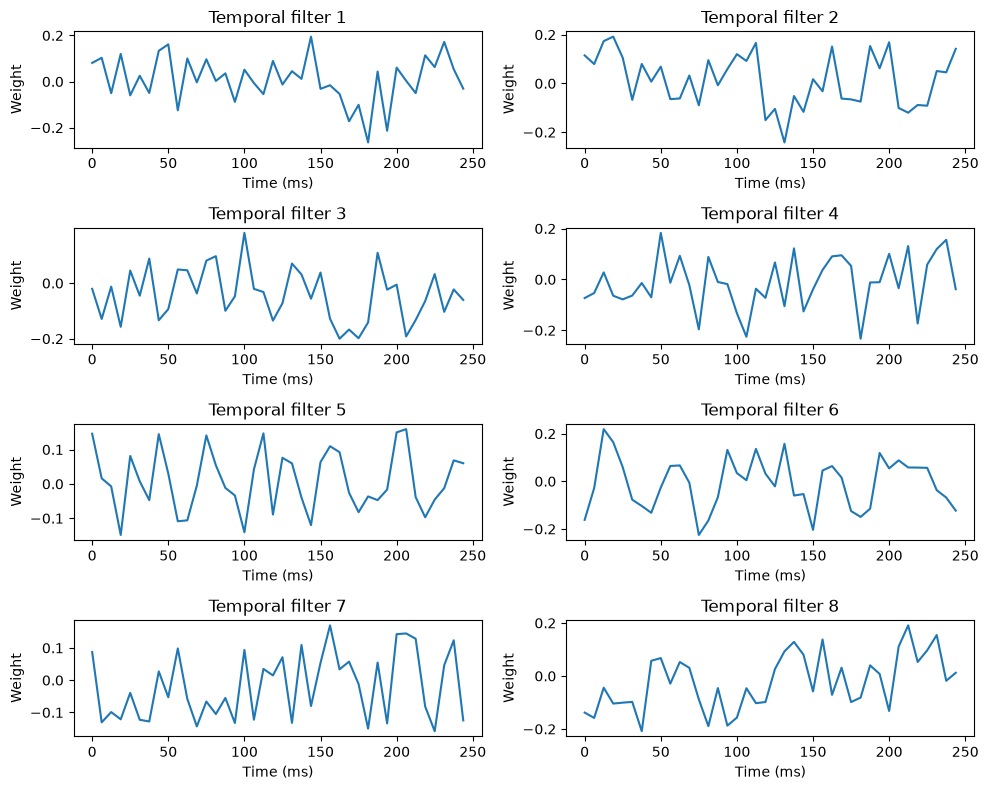

In [5]:
sampling_rate = checkpoint["sampling_rate_hz"]

kernel_samples = temporal_filters.shape[1]

kernel_time_ms = (np.arange(kernel_samples) / sampling_rate * 1000)

fig, axes = plt.subplots(4, 2, figsize=(10, 8))

axes = axes.flatten()

for i in range(8):
    axes[i].plot(kernel_time_ms, temporal_filters[i])

    axes[i].set_title(f"Temporal filter {i + 1}")

    axes[i].set_xlabel("Time (ms)")

    axes[i].set_ylabel("Weight")

plt.tight_layout()

plt.show()

### Fast fourier transform into frequency domain
Note we do not call it amplitude here, because we are not looking at the EEG signal. We are looking at the amplitude of the weight, meaning the magnitude of which it affects the EEG. We therefore call it magnitude here. 

In [6]:
n_fft = 512

frequencies = np.fft.rfftfreq(n_fft, d=1 / sampling_rate)

frequency_responses = []

for i in range(8):

    fft_values = np.fft.rfft(temporal_filters[i], n=n_fft)

    #Amplitude of digital filter
    magnitude = np.abs(fft_values)

    #Normalize amplitude, so 1 = max magnitude
    magnitude = (magnitude / magnitude.max())

    frequency_responses.append(magnitude)

frequency_responses = np.array(frequency_responses)

print("Frequency response shape:", frequency_responses.shape)

Frequency response shape: (8, 257)


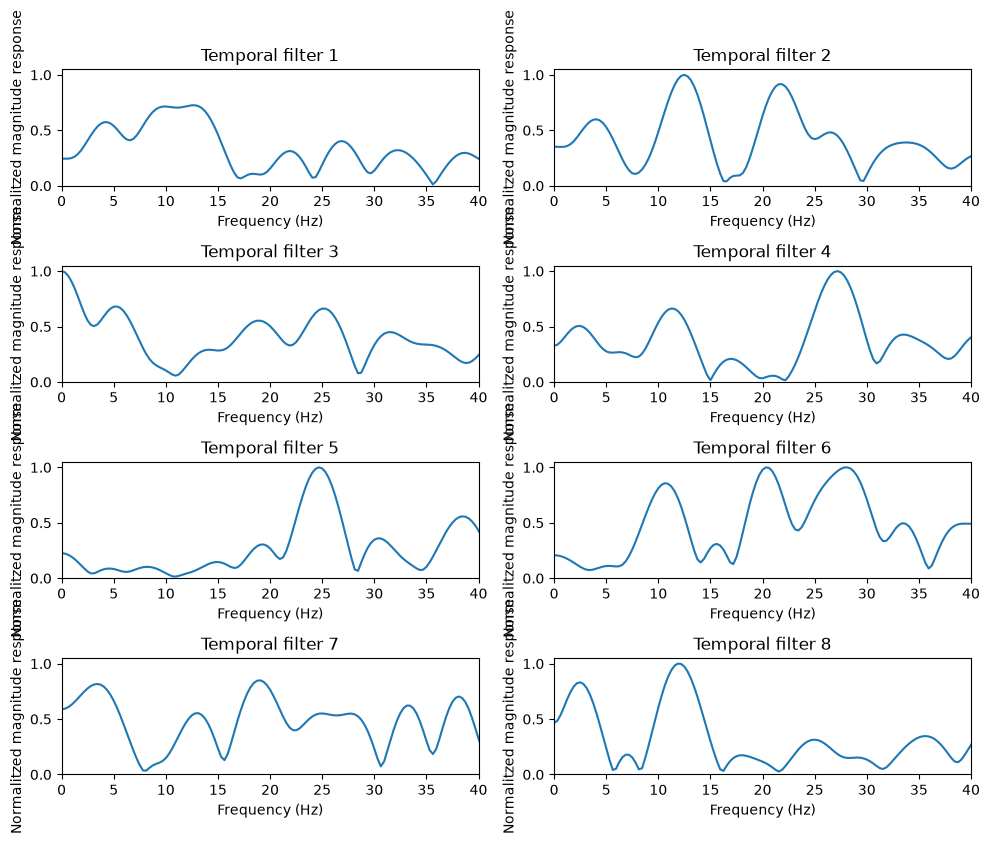

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(10, 8))

axes = axes.flatten()


for i in range(8):

    axes[i].plot(frequencies, frequency_responses[i])

    axes[i].set_xlim(0, 40)

    axes[i].set_ylim(0, 1.05)

    axes[i].set_title(f"Temporal filter {i + 1}")

    axes[i].set_xlabel("Frequency (Hz)")

    axes[i].set_ylabel("Normalitzed magnitude")


plt.tight_layout()

plt.show()

### Find strongest frequencies within each filter

In [12]:
band_mask = ((frequencies >= 7) & (frequencies <= 30))

band_frequencies = frequencies[band_mask]

peak_results = []

for i in range(8):

    band_response = frequency_responses[i, band_mask]

    peak_index = np.argmax(band_response)

    peak_frequency = band_frequencies[peak_index]
    peak_results.append({"filter": i + 1, "peak_frequency_hz": peak_frequency})

    print(f"Filter {i + 1}: " f"{peak_frequency:.2f} Hz")

peak_results = pd.DataFrame(peak_results)

peak_results

Filter 1: 12.50 Hz
Filter 2: 12.50 Hz
Filter 3: 25.00 Hz
Filter 4: 27.19 Hz
Filter 5: 24.69 Hz
Filter 6: 28.12 Hz
Filter 7: 19.06 Hz
Filter 8: 11.88 Hz


,filter,peak_frequency_hz
0,1,12.5000
1,2,12.5000
2,3,25.0000
3,4,27.1875
4,5,24.6875
5,6,28.1250
6,7,19.0625
7,8,11.8750


### Save table

In [13]:
peak_results.to_csv(ROOT / "results" / "week18_temporal_filter_peaks.csv", index=False)

## Learned-filter conclusion

The first temporal convolution of the EEGNet
contains eight learned kernels, each spanning 40 samples (250 ms).

Fourier analysis showed that the kernels learned different frequency
response profiles within the 7–30 Hz band.

Their strongest normalized magnitude occurred between
approximately 12 and 28 Hz. Some filters emphasized lower frequencies
around 12–13 Hz, while others emphasized higher frequencies around
19–28 Hz.

This suggests that the first EEGNet layer learned multiple distinct
temporal transformations.

Because each kernel spans only 250 ms, the precise peak frequencies
should also be interpreted approximately.